# ДЗ 1. Оценка стоимости недвижимости в новостройках Санкт-Петербурга

**Постановка задачи, метрики и разведочный анализ данных Циана.**

Данные самостоятельно собраны мной с помощью парсинга Циана в декабре 2024 года в рамках курса по анализу данных. В этой работе я возвращаюсь к задаче, чтобы глубже исследовать данные и подготовить улучшение ранее полученного решения. Вот [здесь](https://github.com/Ultimatereo/ITMO-UNIVERSITY/tree/main/sem5/data-analysis) можно ознакомиться с изначальной работой.

В работе используются все типы жилья: квартиры, апартаменты и пентхаус. Единица наблюдения — **объявление**. Разные ссылки ещё могут относиться к одной квартире.

## 1. Постановка задачи

**Бизнес-задача:** помочь владельцу или аналитику определить ориентировочную цену предложения по характеристикам объекта. Оценка нужна как отправная точка для сопоставления с похожими предложениями. Завышение может затруднить поиск покупателя, занижение — привести к выбору слишком низкой цены предложения. Данных о сделках, сроках продажи и финансовых последствиях ошибок нет, поэтому стоимость этих последствий я не рассчитываю.

**ML-задача:** регрессия с учителем. Целевая переменная `Стоимость` — цена объявления в рублях. Будущие входы — доступные до назначения цены характеристики: площади, комнатность, этаж, местоположение, тип жилья, отделка и другие свойства объекта. Обучение и сравнение моделей выполняются в ДЗ 2; здесь исследуется пригодность данных.

**Границы применимости:** это исторические цены объявлений, а не цены сделок и не текущая рыночная оценка. Выборка новостроек с одного сайта не представляет весь рынок Санкт-Петербурга. Состав выдачи и наличие характеристик могут смещать выборку. Также стоит учитывать, что данные были собраны под конец 2024 года и уж точно уже не актуальны, однако в рамках данной задачи встаёт интерес выявления точности определении цены по её характеристикам. Для того чтобы применять модель на текущий рынок, необходимо будет скормить свежие данных о квартирах построенной модели обучения.

## 2. Метрики и связь с задачей

Основная метрика — **MAE**, средняя абсолютная ошибка в рублях:

$$
\operatorname{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|
$$

Она непосредственно показывает средний размер отклонения оценки от цены предложения и линейно учитывает величину ошибки. Это понятный пользователю масштаб; при длинном правом хвосте цен MAE менее чувствительна к единичным крупным промахам, чем RMSE, но не игнорирует их.

Дополнительная метрика — **RMSE**:

$$
\operatorname{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}.
$$

Она также выражается в рублях, но сильнее штрафует крупные отклонения. Сочетание MAE и RMSE позволит заметить модель, приемлемую для массового сегмента, но сильно ошибающуюся на дорогих объектах. Обе метрики симметричны к завышению и занижению: оснований задавать разные денежные штрафы пока нет. В ДЗ 2 дополнительно следует показать знаковую ошибку и MAE по типам жилья и ценовым сегментам вместе с числом объектов. Пентхаус представлен единичным наблюдением, поэтому для него нельзя делать устойчивые выводы о качестве.

Метрики будут рассчитаны **в исходных рублях на отложенных данных**, в том числе если модель обучается на логарифме цены. Здесь значений MAE/RMSE модели ещё нет. Выбор лучшей модели и допустимого уровня ошибки потребует честного сравнения с бейзлайном, а не выдуманного порога.

## 3. Воспроизводимость и загрузка

Ноутбук запускается из `HW/` или корня репозитория. Файл читается по относительному пути, сеть и прежний проект для выполнения не нужны. Требуются Python 3.12 и пакеты из `requirements-hw1.txt`: pandas, numpy, matplotlib, openpyxl, IPython, ipykernel, nbformat, nbclient и nbconvert. Установка: `python -m pip install -r HW/requirements-hw1.txt` из корня репозитория (из `HW/` — без префикса `HW/`). Версии среды выполнения выведены ниже.

Проверка в Jupyter: **Restart Kernel and Run All Cells**. В анализе нет случайной выборки или обучения; seed 42 зафиксирован для воспроизводимости возможных случайных операций. Все графики включают весь соответствующий набор наблюдений; локальные ограничения и пропуски явно подсчитываются.

In [137]:
%matplotlib inline

from pathlib import Path
import hashlib
import importlib.metadata as metadata
import platform
import random
import re

import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import numpy as np
import openpyxl
import pandas as pd
from IPython.display import Markdown, display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_columns", 24)
pd.set_option("display.max_rows", 45)
pd.set_option("display.max_colwidth", 85)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.18,
})

versions = {"Python": platform.python_version(), "openpyxl": openpyxl.__version__}
for package in ["pandas", "numpy", "matplotlib", "IPython", "ipykernel",
                "nbformat", "nbclient", "nbconvert"]:
    versions[package] = metadata.version(package)
display(pd.Series(versions, name="Версия").to_frame())

candidates = [Path("data/cian_spb.xlsx"), Path("HW/data/cian_spb.xlsx")]
DATA_PATH = next((path for path in candidates if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Запустите ноутбук из HW/ или корня репозитория.")
raw = pd.read_excel(DATA_PATH, sheet_name="Квартиры СПБ", engine="openpyxl")
source_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print(f"Файл: {DATA_PATH.as_posix()}")
print(f"SHA-256: {source_hash}")
print(f"Исходная таблица: {raw.shape[0]} строк, {raw.shape[1]} столбец.")
display(raw[["Название", "Стоимость", "Общая площадь", "Тип жилья", "ЖК"]].head())

,Версия
Python,3.13.0
openpyxl,3.1.5
pandas,2.3.2
numpy,2.2.4
matplotlib,3.10.6
IPython,9.6.0
ipykernel,7.0.0
nbformat,5.10.4
nbclient,0.10.2
nbconvert,7.16.6


Файл: data/cian_spb.xlsx
SHA-256: 795605d2e2ad8316d5b3ba92a2c62353bb237a5ff9fcd0bb8708620599252b3e
Исходная таблица: 1400 строк, 21 столбец.


,Название,Стоимость,Общая площадь,Тип жилья,ЖК
0,"Студия, 28,7 м²",8843388,"28,7",Новостройка,ЖК «Шкиперский 19»
1,"1-комн. квартира, 36,99 м²",5700000,"36,99",Новостройка,ЖК «Parkolovo (Парколово)»
2,"2-комн. квартира, 53,79 м²",12489000,"53,79",Новостройка,NaN
3,"Апартаменты-студия, 23,37 м²",5609999,"23,37",Новостройка Апартаменты,ЖК «Апарт-отель GloraX Заневский»
4,"1-комн. квартира, 35 м²",5635367,35,Новостройка,ЖК «Монография»


### 3.1. Словарь исходных признаков

Текстовые единицы измерения отражают исходный файл. Типы pandas, заполненность и число уникальных значений проверяются в следующей ячейке.

| Поле | Смысл и единицы | Роль в дальнейшем |
|---|---|---|
| Название | Заголовок объявления: тип планировки, комнаты, площадь | Извлечь комнатность и студию; не подавать сырой текст |
| Ссылка на страницу | URL объявления | Дедупликация и аудит, исключить из модели |
| Локальное место | Путь к HTML в старом проекте | Служебное поле, исключить |
| Просмотры | Число просмотров при сборе | Исключить: зависит от экспозиции и времени, неизвестно при назначении цены |
| Стоимость | Цена предложения, руб. | Целевая переменная |
| ЖК | Название жилого комплекса | Категория и группа для проверки переноса |
| Адрес | Адрес строкой | Извлечь район; сырой адрес пока исключить из входов |
| Метро | Перечень станций строкой | Кандидат на извлечение станций; расстояний и времени в пути нет |
| Общая площадь | Полная площадь объекта, м² | Числовой признак |
| Жилая площадь | Жилая площадь, м² | Числовой признак с пропусками |
| Площадь кухни | Площадь кухни, м² | Числовой признак с пропусками |
| Этаж | «Этаж из этажности» | Два числа и относительное положение в доме |
| Год сдачи | Указанный год сдачи дома | Числовой признак; не дата объявления |
| Отделка | Описанная в объявлении отделка | Категория, «Неизвестно» трактовать как пропуск |
| Тип жилья | Новостройка / апартаменты / пентхаус | Категория, анализировать все три типа |
| Высота потолков | Высота, м; число с суффиксом | Числовой признак с пропусками |
| Санузел | Число и тип санузлов строкой | Категория либо дальнейшее извлечение чисел |
| Вид из окон | Вид во двор, на улицу и т. п. | Категория с большим числом пропусков |
| Количество лифтов | Число и тип лифтов строкой | Кандидат на разбор пассажирских и грузовых лифтов |
| Тип дома | Конструкция дома | Категориальный признак |
| Парковка | Вид парковки | Категория с большим числом пропусков |

In [138]:
schema = pd.DataFrame({
    "Тип pandas": raw.dtypes.astype(str),
    "Заполнено": raw.notna().sum(),
    "Пропуски": raw.isna().sum(),
    "Пропуски, %": raw.isna().mean().mul(100),
    "Уникальных без NA": raw.nunique(),
})
display(schema)
display(raw.select_dtypes(include="number").describe().T)
display(raw["Тип жилья"].value_counts(dropna=False).rename("Объявлений до дедупликации"))

,Тип pandas,Заполнено,Пропуски,"Пропуски, %",Уникальных без NA
Название,object,1400,0,0.00,1103
Ссылка на страницу,object,1400,0,0.00,1328
Локальное место,object,1400,0,0.00,1400
Просмотры,float64,1394,6,0.43,590
Стоимость,int64,1400,0,0.00,1253
ЖК,object,1387,13,0.93,207
Адрес,object,1400,0,0.00,380
Метро,object,1354,46,3.29,232
Общая площадь,object,1400,0,0.00,1019
Жилая площадь,object,1157,243,17.36,332


,count,mean,std,min,25%,50%,75%,max
Просмотры,"1,394.00",446.53,"1,078.19",0.00,34.00,113.00,401.75,"15,490.00"
Стоимость,"1,400.00","12,514,219.85","19,836,977.00","2,800,000.00","5,203,630.00","6,443,472.50","13,890,000.00","268,440,000.00"
Год сдачи,"1,397.00","2,023.78",1.36,"2,012.00","2,023.00","2,024.00","2,025.00","2,026.00"


Тип жилья
Новостройка                1245
Новостройка Апартаменты     154
Новостройка Пентхаус          1
Name: Объявлений до дедупликации, dtype: int64

**Наблюдение.** В исходном файле 1 400 строк и 21 поле; цена и общая площадь заполнены у всех объявлений. При этом площади загружены как строки, а необязательные характеристики часто отсутствуют: например, парковка не указана в 1 036 строках. На этом этапе статистики описывают выгрузку с повторами; далее единица подсчёта — уникальная ссылка. Набора достаточно для учебного эксперимента по регрессии, но небольшой объём и редкие категории ограничат точность оценки качества.

## 4. Повторные объявления

Сначала проверю совпадение **всех** полей внутри одинаковых ссылок, отдельно выделив служебный путь и просмотры. Полное совпадение строк не равно совпадению объявления: путь к сохранённому HTML различается. При одинаковой ссылке сохраняю первую строку в порядке файла. Времени наблюдения нет, поэтому выбрать «самую свежую» запись невозможно. Объявления с отсутствующим URL, если они встретятся, не объединяются между собой.

In [139]:
LINK = "Ссылка на страницу"
duplicate_mask = raw[LINK].notna() & raw.duplicated(LINK, keep=False)
duplicate_rows = raw.loc[duplicate_mask]
variation = duplicate_rows.groupby(LINK).nunique(dropna=False)
conflict_counts = variation.gt(1).sum().rename("Ссылок с расхождениями")
display(conflict_counts.to_frame())

business_fields = raw.columns.difference([LINK, "Локальное место", "Просмотры"])
business_conflicts = variation[business_fields].gt(1).any(axis=1)
conflict_records = []
for link, group in duplicate_rows.groupby(LINK, sort=False):
    for column in raw.columns.difference([LINK, "Локальное место"]):
        if group[column].nunique(dropna=False) > 1:
            conflict_records.append({
                "Ссылка": link,
                "Поле": column,
                "Значения в порядке файла": group[column].tolist(),
                "Оставлено первое": group[column].iloc[0],
            })
conflict_details = pd.DataFrame(conflict_records)
display(conflict_details)

removed_duplicate_mask = raw[LINK].notna() & raw.duplicated(LINK, keep="first")
df = raw.loc[~removed_duplicate_mask].copy()
df.insert(0, "Строка Excel", df.index + 2)
dedup_audit = pd.Series({
    "Исходных строк": len(raw),
    "Полностью повторных строк": int(raw.duplicated().sum()),
    "Отсутствует ссылка": int(raw[LINK].isna().sum()),
    "Уникальных непустых ссылок": raw[LINK].nunique(),
    "Ссылок с повторениями": len(variation),
    "Строк в повторяющихся группах": len(duplicate_rows),
    "Групп с расхождением характеристик или цены": int(business_conflicts.sum()),
    "Удалено повторных строк": int(removed_duplicate_mask.sum()),
    "Осталось строк": len(df),
}, name="Количество")
display(dedup_audit.to_frame())

,Ссылок с расхождениями
Название,0
Локальное место,72
Просмотры,4
Стоимость,0
ЖК,0
Адрес,0
Метро,0
Общая площадь,0
Жилая площадь,0
Площадь кухни,0


,Ссылка,Поле,Значения в порядке файла,Оставлено первое
0,https://spb.cian.ru/sale/flat/291317386/,Просмотры,"[143.0, 142.0]",143.00
1,https://spb.cian.ru/sale/flat/292296886/,Просмотры,"[139.0, 140.0]",139.00
2,https://spb.cian.ru/sale/flat/273821194/,Просмотры,"[4696.0, 4697.0]","4,696.00"
3,https://spb.cian.ru/sale/flat/290445557/,Просмотры,"[898.0, 897.0]",898.00


,Количество
Исходных строк,1400
Полностью повторных строк,0
Отсутствует ссылка,0
Уникальных непустых ссылок,1328
Ссылок с повторениями,72
Строк в повторяющихся группах,144
Групп с расхождением характеристик или цены,0
Удалено повторных строк,72
Осталось строк,1328


**Результат.** Получено 1 328 уникальных ссылок. В 72 группах по две строки различается локальный путь, а в четырёх группах — просмотры (значения приведены выше). Цена и остальные характеристики совпадают во всех повторных группах. Удалены ровно 72 повторные строки; полностью одинаковых строк нет. Поэтому сохранение первой записи не меняет исследуемые характеристики. Дедупликация по URL не исключает повторную публикацию одного объекта под разными ссылками; поиск таких случаев потребовал бы дополнительного идентификатора или ручной проверки адреса и планировки.

## 5. Преобразование признаков

Площади перевожу из десятичных строк с запятой в м², высоту потолков — в метры. Регулярные выражения проверяют всю строку: непонятный формат не превращается в произвольное число. Разбираю этаж/этажность и название. Для студии условно задаю `Комнат = 0` и отдельный признак `Студия`; это кодировка планировки, а не утверждение об отсутствии жилого пространства. «Многокомнатная» и свободная планировка остаются без точного числа комнат, но сохраняются в категориальной комнатности.

Район извлекается только после явного `р-н` в адресе. Пропущенный район не угадывается по названию улицы. `Неизвестно` в отделке приравнивается к отсутствию сведений. Все исходные строки сохранены в `raw`, исходные поля после дедупликации — в `df`; подготовленные признаки добавляются отдельными столбцами. Обучаемые заполнение пропусков, кодирование и масштабирование здесь не выполняются.

In [140]:
parse_audit = []


def record_parse(source, result, new_name):
    """Подсчитать исходные пропуски и непустые нераспознанные строки."""
    parse_audit.append({
        "Новый признак": new_name,
        "Строк": len(source),
        "Пропуски источника": int(source.isna().sum()),
        "Распознано": int(result.notna().sum()),
        "Не распознано из непустых": int((source.notna() & result.isna()).sum()),
        "Пропуски результата": int(result.isna().sum()),
    })


def parse_measure(source, unit_pattern):
    """Число с запятой/точкой и необязательной единицей измерения."""
    normalized = source.astype("string").str.replace("\u00a0", " ").str.strip()
    pattern = rf"^([+-]?[0-9]+(?:[.,][0-9]+)?)\s*(?:{unit_pattern})?$"
    values = normalized.str.extract(pattern, expand=False).str.replace(",", ".", regex=False)
    return pd.to_numeric(values, errors="coerce").astype("Float64")


area_mapping = {
    "Общая площадь": "Общая площадь, м²",
    "Жилая площадь": "Жилая площадь, м²",
    "Площадь кухни": "Площадь кухни, м²",
}
for source, target in area_mapping.items():
    df[target] = parse_measure(df[source], r"м²|м2")
    record_parse(df[source], df[target], target)

df["Потолки, м"] = parse_measure(df["Высота потолков"], r"м")
record_parse(df["Высота потолков"], df["Потолки, м"], "Потолки, м")

floor_parts = df["Этаж"].astype("string").str.extract(r"^\s*(\d+)\s+из\s+(\d+)\s*$")
for position, target in enumerate(["Этаж, число", "Этажность"]):
    df[target] = pd.to_numeric(floor_parts[position], errors="coerce").astype("Int64")
    record_parse(df["Этаж"], df[target], target)

title = df["Название"].astype("string").str.lower().str.strip()
studio = title.str.match(r"^(?:апартаменты-)?студия\b", na=False)
rooms = pd.to_numeric(title.str.extract(r"^(\d+)-комн\.", expand=False), errors="coerce")
multi = title.str.startswith("многокомнатная", na=False)
free = title.str.startswith("квартира свободной планировки", na=False)
df["Комнат"] = rooms.mask(studio, 0).astype("Int64")
df["Студия"] = pd.Series(pd.NA, index=df.index, dtype="boolean")
df.loc[rooms.notna() | multi | free, "Студия"] = False
df.loc[studio, "Студия"] = True
df["Комнатность"] = df["Комнат"].astype("string").add("-комнатная")
df.loc[studio, "Комнатность"] = "Студия"
df.loc[multi, "Комнатность"] = "Многокомнатная"
df.loc[free, "Комнатность"] = "Свободная планировка"
for target in ["Комнат", "Студия", "Комнатность"]:
    record_parse(df["Название"], df[target], target)

df["Район"] = df["Адрес"].astype("string").str.extract(r"р-н\s+([^\s,]+)", expand=False)
record_parse(df["Адрес"], df["Район"], "Район")
type_mapping = {
    "Новостройка": "Квартира",
    "Новостройка Апартаменты": "Апартаменты",
    "Новостройка Пентхаус": "Пентхаус",
}
df["Категория жилья"] = df["Тип жилья"].map(type_mapping).astype("string")
record_parse(df["Тип жилья"], df["Категория жилья"], "Категория жилья")
df["Отделка, категория"] = df["Отделка"].astype("string").replace("Неизвестно", pd.NA)
df["Доля этажа"] = df["Этаж, число"] / df["Этажность"].where(df["Этажность"] > 0)
df["Первый этаж"] = df["Этаж, число"].eq(1)
df["Последний этаж"] = df["Этаж, число"].eq(df["Этажность"])

display(pd.DataFrame(parse_audit).set_index("Новый признак"))
print("Заменено значений 'Неизвестно' в отделке:", df["Отделка"].eq("Неизвестно").sum())
print("Пропусков отделки до / после:", df["Отделка"].isna().sum(),
      df["Отделка, категория"].isna().sum())
print("Не удалось определить точное число комнат:")
display(df.loc[df["Комнат"].isna(), ["Строка Excel", "Название", "Комнатность"]])
print("Адреса без явного района:")
display(df.loc[df["Район"].isna(), ["Строка Excel", "Адрес"]])
display(df[["Стоимость", *area_mapping.values(), "Потолки, м", "Этаж, число",
            "Этажность", "Комнат", "Год сдачи"]].describe(
                percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).T)

,Строк,Пропуски источника,Распознано,Не распознано из непустых,Пропуски результата
Новый признак,,,,,
"Общая площадь, м²",1328,0,1328,0,0
"Жилая площадь, м²",1328,226,1102,0,226
"Площадь кухни, м²",1328,544,784,0,544
"Потолки, м",1328,435,893,0,435
"Этаж, число",1328,0,1328,0,0
Этажность,1328,0,1328,0,0
Комнат,1328,0,1322,6,6
Студия,1328,0,1328,0,0
Комнатность,1328,0,1328,0,0


Заменено значений 'Неизвестно' в отделке: 44
Пропусков отделки до / после: 114 158
Не удалось определить точное число комнат:


,Строка Excel,Название,Комнатность
450,452,"Многокомнатная квартира, 216,52 м²",Многокомнатная
880,882,"Многокомнатная квартира, 216,56 м²",Многокомнатная
932,934,"Многокомнатная квартира, 288,2 м²",Многокомнатная
935,937,"Многокомнатная квартира, 229 м²",Многокомнатная
937,939,"Многокомнатная квартира, 309,6 м²",Многокомнатная
938,940,"Квартира свободной планировки, 355,9 м²",Свободная планировка


Адреса без явного района:


,Строка Excel,Адрес
156,158,Санкт-Петербург Шушары поселок Пулковское территория ул. Кокколевская 14к1
173,175,Санкт-Петербург Шушары поселок ул. Соколиная 7к1
377,379,Санкт-Петербург Звездное муниципальный округ Триумф Парк жилой комплекс
832,834,Санкт-Петербург Большой Сампсониевский просп. 70к3
941,943,Санкт-Петербург Шушары поселок Аэросити Клаб жилой комплекс


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Стоимость,"1,328.00","12,523,297.36","20,229,014.01","2,800,000.00","5,198,850.00","6,402,574.50","12,956,624.50","25,599,929.70","36,870,729.85","98,993,279.70","268,440,000.00"
"Общая площадь, м²","1,328.00",45.30,35.10,15.85,25.54,33.78,48.35,85.71,113.74,183.64,355.90
"Жилая площадь, м²","1,102.00",20.81,15.07,6.60,12.20,15.80,22.70,39.77,51.88,77.39,159.90
"Площадь кухни, м²",784.00,13.35,7.12,2.00,6.88,13.40,17.10,21.84,25.18,35.10,48.20
"Потолки, м",893.00,2.81,0.30,2.50,2.70,2.75,2.87,3.00,3.06,3.65,7.00
"Этаж, число","1,328.00",5.08,4.67,1.00,2.00,3.00,7.00,12.00,15.00,22.00,26.00
Этажность,"1,328.00",12.54,5.96,3.00,8.00,12.00,15.25,23.00,24.00,26.00,30.00
Комнат,"1,322.00",1.01,1.15,0.00,0.00,1.00,2.00,3.00,3.00,4.00,5.00
Год сдачи,"1,325.00","2,023.79",1.36,"2,012.00","2,023.00","2,024.00","2,025.00","2,025.00","2,026.00","2,026.00","2,026.00"


**Результат.** Все непустые площади, высоты потолков и этажи разобраны. Точное число комнат неизвестно у шести объектов: пяти многокомнатных квартир и одной квартиры свободной планировки. Их категории сохранены. В пяти адресах нет явного района. Эти строки остаются в выборке с пропуском соответствующего признака. 44 значения отделки «Неизвестно» объединены с 114 исходными пропусками: всего 158. Нулём необязательные характеристики не заполняются, поскольку отсутствие сведений не равно отсутствию кухни, парковки или потолка.

## 6. Проверки качества и аномалии

Проверю цену и площади на положительность, части площади — на согласованность с общей, этаж — на принадлежность дому. Для суммы жилой площади и кухни допускается 0,1 м² на округление. Равенство этой суммы общей площади не требуется: существуют коридоры и другие помещения. В таблице отдельно указаны число проверяемых строк и число строк без достаточных данных.

Высота потолков вне диапазона 2–5 м — сигнал ручной проверки, а не доказанная ошибка. Цена за м² рассчитывается только для положительных цены и общей площади и используется **исключительно в EDA**, поскольку содержит целевую переменную. Дорогие объявления отмечаются правилом 1,5 IQR для диагностики, без удаления или обрезания хвоста.

In [141]:
checks = []
anomaly_flags = pd.DataFrame(index=df.index)


def check_rule(name, columns, bad):
    eligible = df[columns].notna().all(axis=1)
    flagged = eligible & bad.fillna(False)
    anomaly_flags[name] = flagged
    checks.append({
        "Проверка": name,
        "Проверено": int(eligible.sum()),
        "Недостаточно данных": int((~eligible).sum()),
        "Нарушений / сигналов": int(flagged.sum()),
    })


for column in ["Стоимость", *area_mapping.values()]:
    check_rule(f"{column} ≤ 0", [column], df[column].le(0))
check_rule("Жилая > общая", ["Жилая площадь, м²", "Общая площадь, м²"],
           df["Жилая площадь, м²"].gt(df["Общая площадь, м²"]))
check_rule("Кухня > общая", ["Площадь кухни, м²", "Общая площадь, м²"],
           df["Площадь кухни, м²"].gt(df["Общая площадь, м²"]))
check_rule("Жилая + кухня > общей + 0,1 м²", list(area_mapping.values()),
           (df["Жилая площадь, м²"] + df["Площадь кухни, м²"])
           .gt(df["Общая площадь, м²"] + 0.1))
check_rule("Этаж вне границ дома", ["Этаж, число", "Этажность"],
           df["Этаж, число"].lt(1) | df["Этажность"].lt(1)
           | df["Этаж, число"].gt(df["Этажность"]))
check_rule("Потолки вне 2–5 м (проверить)", ["Потолки, м"],
           df["Потолки, м"].lt(2) | df["Потолки, м"].gt(5))
display(pd.DataFrame(checks).set_index("Проверка"))
display(df.loc[anomaly_flags.any(axis=1), [
    "Строка Excel", "Название", "Стоимость", "Потолки, м", "ЖК", LINK,
]])

valid_price_area = df["Стоимость"].gt(0) & df["Общая площадь, м²"].gt(0)
df["Цена за м², руб."] = (
    df["Стоимость"] / df["Общая площадь, м²"]
).where(valid_price_area)
df["Стоимость, млн руб."] = df["Стоимость"] / 1_000_000
df["Цена за м², тыс. руб."] = df["Цена за м², руб."] / 1_000
q1, q3 = df["Стоимость"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
high_price = df["Стоимость"].gt(upper_fence)
print(f"Граница 1,5 IQR: {upper_fence:,.2f} руб.; выше границы: {high_price.sum()}.")
display(df.nlargest(8, "Стоимость")[[
    "Строка Excel", "Название", "Категория жилья", "Стоимость, млн руб.",
    "Общая площадь, м²", "Цена за м², тыс. руб.", "ЖК",
]])
print("Годы сдачи:")
display(df.groupby("Год сдачи", dropna=False).size().rename("Объявлений"))

row_audit = pd.DataFrame({
    "Этап": ["Исходный файл", "Удаление повторных URL", "Разбор признаков",
             "Проверки и аномалии", "Необязательные пропуски", "Итог EDA"],
    "Удалено на этапе": [0, int(removed_duplicate_mask.sum()), 0, 0, 0, 0],
    "Осталось": [len(raw), len(df), len(df), len(df), len(df), len(df)],
})
display(row_audit)

,Проверено,Недостаточно данных,Нарушений / сигналов
Проверка,,,
Стоимость ≤ 0,1328,0,0
"Общая площадь, м² ≤ 0",1328,0,0
"Жилая площадь, м² ≤ 0",1102,226,0
"Площадь кухни, м² ≤ 0",784,544,0
Жилая > общая,1102,226,0
Кухня > общая,784,544,0
"Жилая + кухня > общей + 0,1 м²",752,576,0
Этаж вне границ дома,1328,0,0
Потолки вне 2–5 м (проверить),893,435,2


,Строка Excel,Название,Стоимость,"Потолки, м",ЖК,Ссылка на страницу
35,37,"3-комн. квартира, 107,3 м²",43499957,7.00,ЖК «Маленькая Франция»,https://spb.cian.ru/sale/flat/291921033/
923,925,"2-комн. квартира, 70,1 м²",32806239,7.00,ЖК «Маленькая Франция»,https://spb.cian.ru/sale/flat/291921028/


Граница 1,5 IQR: 24,593,286.25 руб.; выше границы: 136.


,Строка Excel,Название,Категория жилья,"Стоимость, млн руб.","Общая площадь, м²","Цена за м², тыс. руб.",ЖК
940,942,"3-комн. квартира, 227,95 м²",Квартира,268.44,227.95,"1,177.63",ЖК «Приоритет»
939,941,"4-комн. квартира, 246,07 м²",Квартира,264.77,246.07,"1,075.99",ЖК «Приоритет»
938,940,"Квартира свободной планировки, 355,9 м²",Квартира,236.34,355.90,664.05,ЖК «Три грации»
279,281,"4-комн. квартира, 254,7 м²",Квартира,231.00,254.70,906.95,ЖК «Клубный дом Крестовский IV»
257,259,"3-комн. квартира, 325,2 м²",Квартира,198.00,325.20,608.86,ЖК «Клубный дом Крестовский IV»
937,939,"Многокомнатная квартира, 309,6 м²",Квартира,153.61,309.60,496.15,ЖК «Три грации»
450,452,"Многокомнатная квартира, 216,52 м²",Пентхаус,149.70,216.52,691.40,ЖК «Северная Корона»
936,938,"5-комн. квартира, 232,3 м²",Квартира,135.90,232.30,585.00,ЖК «Victory Plaza (Виктори Плаза)»


Годы сдачи:


Год сдачи
2,012.00      1
2,014.00      1
2,019.00      7
2,020.00     13
2,021.00     31
2,022.00    124
2,023.00    368
2,024.00    345
2,025.00    332
2,026.00    103
NaN           3
Name: Объявлений, dtype: int64

,Этап,Удалено на этапе,Осталось
0,Исходный файл,0,1400
1,Удаление повторных URL,72,1328
2,Разбор признаков,0,1328
3,Проверки и аномалии,0,1328
4,Необязательные пропуски,0,1328
5,Итог EDA,0,1328


**Результат и решение.** Неположительных цен/площадей, нарушений границ этажей и несогласованных площадей среди проверяемых строк нет. В двух объявлениях ЖК «Маленькая Франция» указаны потолки 7 м. Это на самом деле особенность данного ЖК, согласно интернету, что удивительно и очевидным образом не является ошибкой, но достаточно выбивающимся значением.

Выше границы 1,5 IQR (24,59 млн руб.) находятся 136 объявлений. Максимальная цена — 268,44 млн руб.; дорогие квартиры сочетают большие площади и высокую цену за м². Статистический хвост сам по себе не является ошибкой. Все такие объявления, включая пентхаус, сохранены. Годы сдачи лежат между 2012 и 2026 годами: их нельзя интерпретировать как время сбора или автоматически отфильтровывать уже сданные дома. Итоговый EDA содержит 1 328 строк; единственное исключение строк — 72 повтора URL.

## 7. Распределения стоимости, площади и цены за м²

Для каждого показателя приведены обычная гистограмма и гистограмма с равномерными интервалами в логарифме и логарифмической осью X. Это позволяет одновременно увидеть полный диапазон и массовый сегмент. На всех графиках `n` — число непустых наблюдений; для логарифма дополнительно требуется положительность. Хвосты не обрезаются.

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
"Стоимость, млн руб.","1,328.00",12.52,20.23,2.80,5.20,6.40,12.96,25.60,36.87,98.99,268.44
"Общая площадь, м²","1,328.00",45.30,35.10,15.85,25.54,33.78,48.35,85.71,113.74,183.64,355.90
"Цена за м², тыс. руб.","1,328.00",234.88,100.33,100.51,170.79,208.71,266.65,351.29,418.50,589.16,"1,177.63"


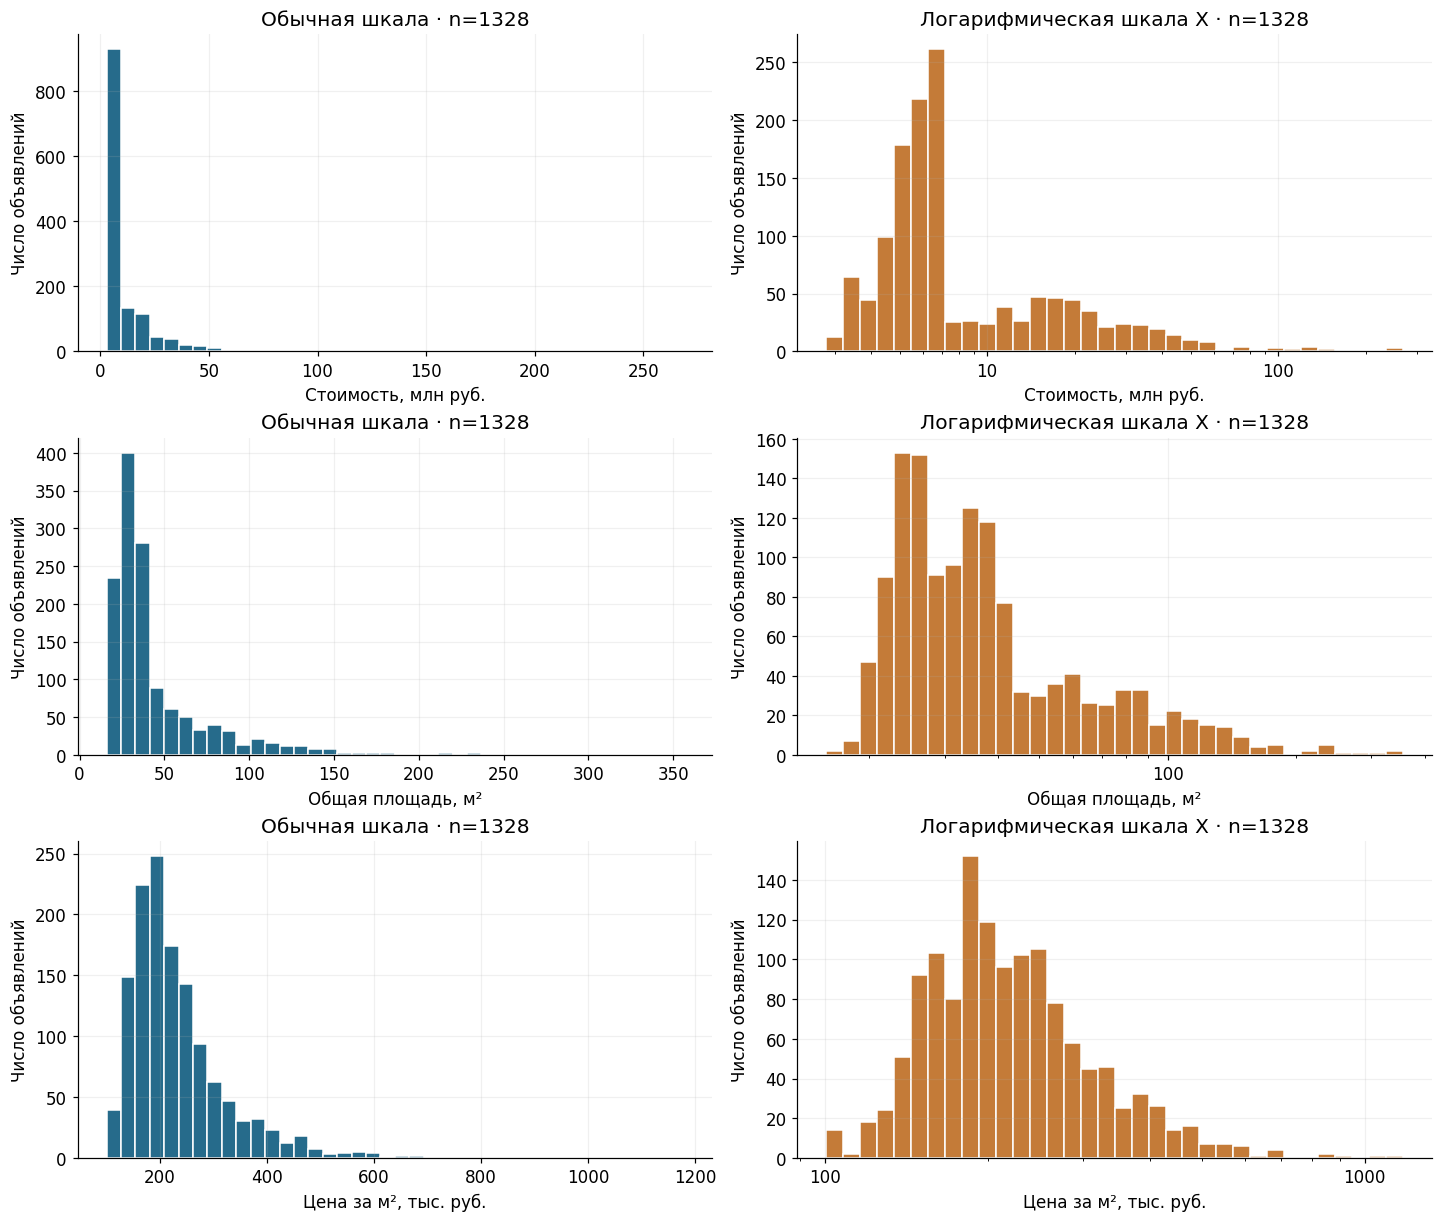

,Показатель,Всего,Пропущено NA,Неположительных для log
0,"Стоимость, млн руб.",1328,0,0
1,"Общая площадь, м²",1328,0,0
2,"Цена за м², тыс. руб.",1328,0,0


In [142]:
distribution_columns = ["Стоимость, млн руб.", "Общая площадь, м²", "Цена за м², тыс. руб."]
display(df[distribution_columns].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).T)
fig, axes = plt.subplots(3, 2, figsize=(13, 11), layout="constrained")
distribution_audit = []
for row, column in enumerate(distribution_columns):
    values = df[column].dropna().astype(float)
    positive = values.loc[values > 0]
    axes[row, 0].hist(values, bins=40, color="#266B8B", edgecolor="white")
    axes[row, 0].set_title(f"Обычная шкала · n={len(values)}")
    bins = np.geomspace(positive.min(), positive.max(), 35)
    axes[row, 1].hist(positive, bins=bins, color="#C47B38", edgecolor="white")
    axes[row, 1].set_xscale("log")
    axes[row, 1].xaxis.set_major_formatter(ScalarFormatter())
    axes[row, 1].set_title(f"Логарифмическая шкала X · n={len(positive)}")
    for ax in axes[row]:
        ax.set_xlabel(column)
        ax.set_ylabel("Число объявлений")
    distribution_audit.append({"Показатель": column, "Всего": len(df),
                               "Пропущено NA": len(df) - len(values),
                               "Неположительных для log": len(values) - len(positive)})
plt.show()
display(pd.DataFrame(distribution_audit))

**Интерпретация.** Средняя стоимость 12,52 млн руб. заметно выше медианы 6,40 млн руб., а максимум достигает 268,44 млн руб. Это длинный правый хвост, из-за которого обычная шкала сжимает массовый сегмент. Медианная площадь — 33,78 м², 90-й процентиль — 85,71 м². Медианная цена за м² — 208,71 тыс. руб., 99-й процентиль — 589,16 тыс. руб. Все 1 328 объектов положительны и представлены на обеих шкалах.

Для будущей модели разумно проверить преобразование целевой переменной логарифмом и устойчивость ошибки по ценовым сегментам. Улучшение от логарифма не гарантировано: оптимизация в логарифмах меняет вес относительных и абсолютных ошибок, а итоговое сравнение всё равно проводится по MAE/RMSE в рублях. Цена за м² здесь описывает рынок внутри выборки и не становится признаком модели.

## 8. Связь стоимости с площадью

На диаграмме рассеяния цвет показывает тип жилья; пентхаус выделен отдельным маркером. Логарифмические шкалы дают возможность рассмотреть малые и крупные объекты одновременно. Корреляции вычисляются по доступным парам; число пар выводится отдельно.

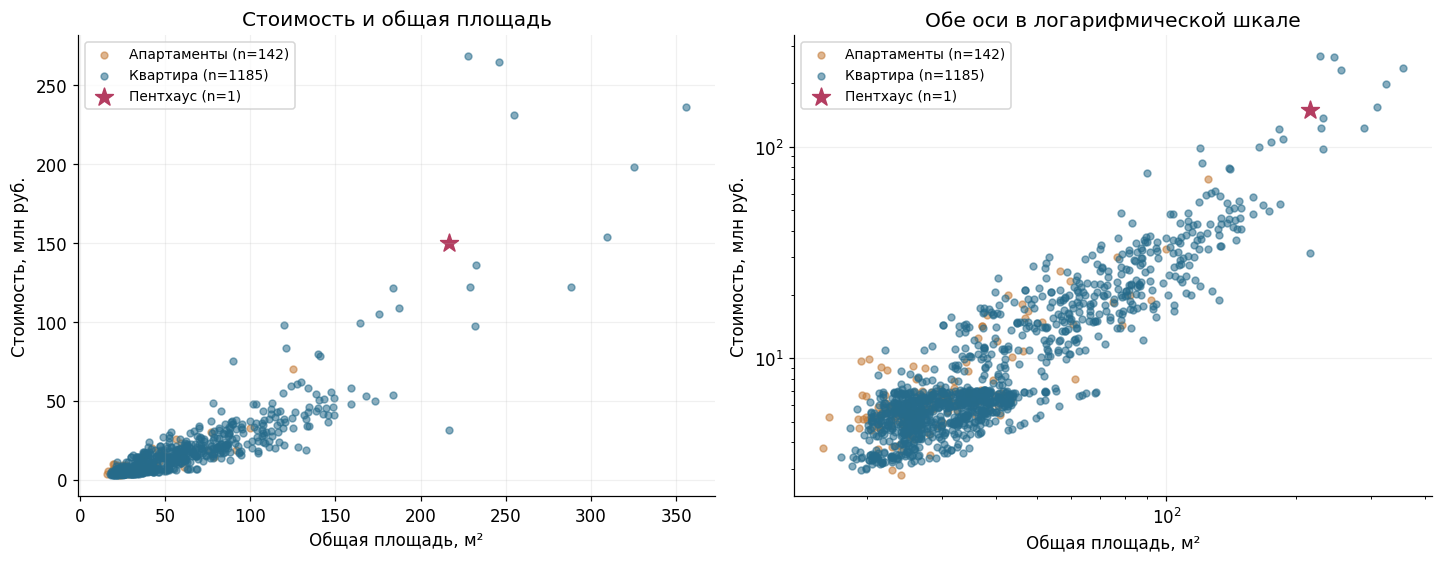

,Пар,Без пары,Пирсон,Спирмен
Признак,,,,
"Общая площадь, м²",1328,0,0.86,0.80
"Жилая площадь, м²",1102,226,0.77,0.58
"Площадь кухни, м²",784,544,0.52,0.67
Комнат,1322,6,0.59,0.73
"Этаж, число",1328,0,0.02,0.10
Этажность,1328,0,-0.16,-0.11
"Потолки, м",893,435,0.37,0.47


In [143]:
colors = {"Квартира": "#266B8B", "Апартаменты": "#C47B38", "Пентхаус": "#B43D61"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for category, group in df.groupby("Категория жилья", dropna=False):
    valid = group[["Общая площадь, м²", "Стоимость, млн руб."]].dropna()
    for ax in axes:
        ax.scatter(valid["Общая площадь, м²"], valid["Стоимость, млн руб."],
                   label=f"{category} (n={len(valid)})", c=colors.get(category, "gray"),
                   alpha=0.55 if category != "Пентхаус" else 1,
                   marker="*" if category == "Пентхаус" else "o",
                   s=150 if category == "Пентхаус" else 20)
axes[0].set_title("Стоимость и общая площадь")
axes[1].set_title("Обе оси в логарифмической шкале")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("Общая площадь, м²")
    ax.set_ylabel("Стоимость, млн руб.")
    ax.legend(fontsize=9)
plt.show()

correlations = []
for column in [*area_mapping.values(), "Комнат", "Этаж, число", "Этажность", "Потолки, м"]:
    pair = df[["Стоимость", column]].dropna().astype(float)
    correlations.append({
        "Признак": column, "Пар": len(pair), "Без пары": len(df) - len(pair),
        "Пирсон": pair.corr().iloc[0, 1],
        "Спирмен": pair.rank().corr().iloc[0, 1],
    })
display(pd.DataFrame(correlations).set_index("Признак"))

**Интерпретация.** Ранговая корреляция стоимости и общей площади составляет около 0,80 на 1 328 парах. Площадь — сильный кандидат в модель, но объекты одинаковой площади заметно различаются по цене. Апартаменты и квартиры перекрываются на графике; одного типа жилья недостаточно для объяснения цены. Корреляция не доказывает причинный эффект площади или других характеристик: район, ЖК и класс проекта могут влиять одновременно. Жилая площадь, кухня и общая площадь связаны между собой, поэтому для линейной модели нужно учитывать зависимость признаков и проверять регуляризацию.

## 9. Сравнение категорий

Для каждой группы приведены размер, медиана цены, квартильный интервал, медиана площади и цены за м². У коробчатых диаграмм показаны все выбросы; ось цены логарифмическая. Малые группы не удаляются, но не используются для уверенного ранжирования. Группа «Не указано» обозначает пропуск только в отчёте и не заполняет исходные признаки.

In [144]:
def group_summary(column):
    """Сводка с числом строк, включая группу с пропущенным признаком."""
    work = df.assign(Группа=df[column].astype("string").fillna("Не указано"))
    return work.groupby("Группа", sort=False).agg(
        n=("Стоимость", "size"),
        цена_Q1=("Стоимость, млн руб.", lambda x: x.quantile(0.25)),
        цена_медиана=("Стоимость, млн руб.", "median"),
        цена_Q3=("Стоимость, млн руб.", lambda x: x.quantile(0.75)),
        площадь_медиана=("Общая площадь, м²", "median"),
        м2_медиана=("Цена за м², тыс. руб.", "median"),
    ).rename(columns={
        "цена_Q1": "Цена Q1, млн руб.", "цена_медиана": "Цена медиана, млн руб.",
        "цена_Q3": "Цена Q3, млн руб.", "площадь_медиана": "Площадь медиана, м²",
        "м2_медиана": "Медиана тыс. руб./м²",
    })


def group_plot(column, title, order=None, per_m2=False):
    groups = df[column].astype("string").fillna("Не указано")
    summary = group_summary(column)
    if order is None:
        order = summary.sort_values("Цена медиана, млн руб.").index.tolist()
    order = [value for value in order if value in summary.index]
    value_column = "Цена за м², тыс. руб." if per_m2 else "Стоимость, млн руб."
    arrays = [df.loc[groups.eq(group), value_column].dropna().astype(float) for group in order]
    labels = [f"{group} (n={summary.loc[group, 'n']})" for group in order]
    fig, ax = plt.subplots(figsize=(11, max(3.5, len(order) * 0.43)), layout="constrained")
    ax.boxplot(arrays, orientation="horizontal", tick_labels=labels, patch_artist=True,
               boxprops={"facecolor": "#C5DCE6"}, medianprops={"color": "#A34B20"},
               flierprops={"marker": ".", "markersize": 4, "alpha": 0.5})
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.set_xlabel(value_column + " · логарифмическая шкала")
    ax.set_title(title)
    plt.show()
    display(summary.loc[order])
    print(f"Показано {sum(len(values) for values in arrays)} из {len(df)} объявлений.")
    return summary

### 9.1. Комнатность

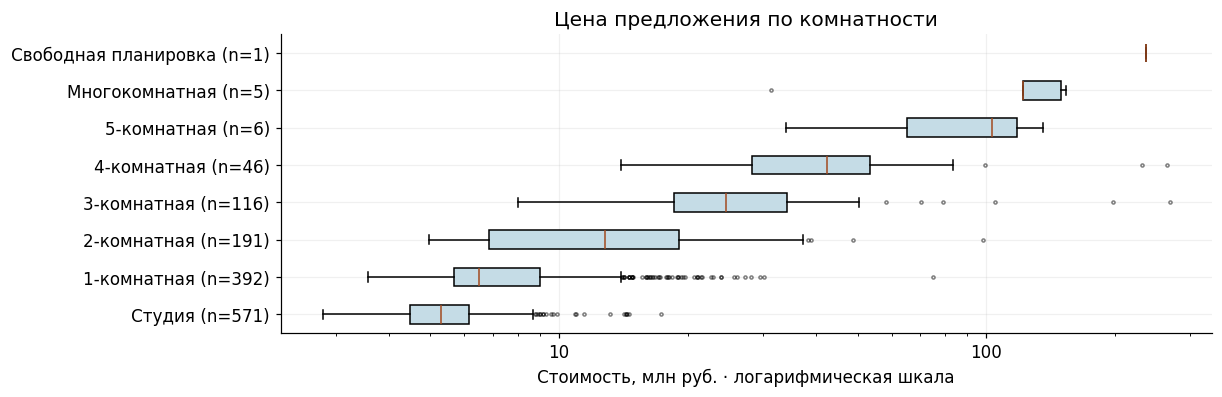

,n,"Цена Q1, млн руб.","Цена медиана, млн руб.","Цена Q3, млн руб.","Площадь медиана, м²",Медиана тыс. руб./м²
Группа,,,,,,
Студия,571,4.47,5.30,6.16,24.95,211.71
1-комнатная,392,5.69,6.50,9.02,36.69,183.78
2-комнатная,191,6.85,12.78,19.12,56.00,222.44
3-комнатная,116,18.56,24.55,34.18,87.99,272.01
4-комнатная,46,28.33,42.36,53.48,128.85,308.70
5-комнатная,6,65.17,103.07,118.03,185.25,500.98
Многокомнатная,5,121.94,122.17,149.70,229.00,496.15
Свободная планировка,1,236.34,236.34,236.34,355.90,664.05


Показано 1328 из 1328 объявлений.


In [145]:
room_order = ["Студия", "1-комнатная", "2-комнатная", "3-комнатная", "4-комнатная",
              "5-комнатная", "Многокомнатная", "Свободная планировка", "Не указано"]
room_summary = group_plot("Комнатность", "Цена предложения по комнатности", room_order)

**Интерпретация.** Студий 571, однокомнатных объектов 392: вместе 963 из 1 328 (72,5%). Медиана стоимости возрастает от 5,30 млн руб. у студий до 6,50 млн у однокомнатных, 12,78 млн у двухкомнатных и 24,55 млн у трёхкомнатных. При этом увеличивается и медианная площадь, поэтому нельзя приписать разницу только комнатности. Для пятикомнатных есть лишь шесть наблюдений, многокомнатных — пять, свободной планировки — одно. Точная комнатность и признак студии дополнят площади, а редкие планировки потребуют осторожного кодирования и отдельного контроля ошибок.

### 9.2. Район

Показываю цену за м², чтобы частично отделить различия размера объекта от различий местоположения. Это не устраняет влияние класса ЖК, отделки и состава предложения.

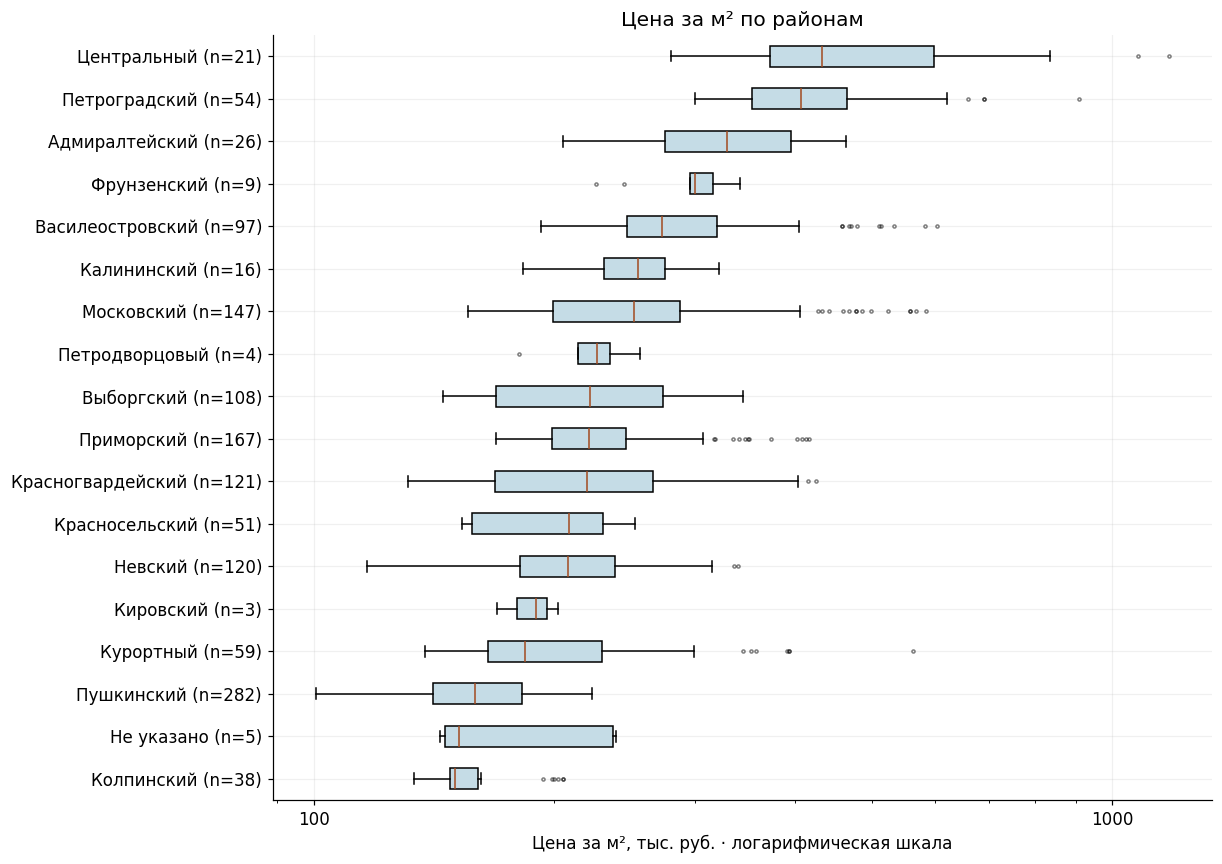

,n,"Цена Q1, млн руб.","Цена медиана, млн руб.","Цена Q3, млн руб.","Площадь медиана, м²",Медиана тыс. руб./м²
Группа,,,,,,
Колпинский,38,3.39,4.81,6.16,25.58,150.26
Не указано,5,6.15,6.22,6.86,42.61,152.00
Пушкинский,282,4.37,5.07,6.20,33.30,159.15
Курортный,59,5.34,6.43,7.04,34.67,183.94
Кировский,3,4.88,4.89,5.46,25.77,189.67
Невский,120,5.22,6.07,6.84,27.40,207.86
Красносельский,51,5.50,5.70,6.52,27.27,208.98
Красногвардейский,121,4.74,5.70,10.95,28.38,219.76
Приморский,167,5.65,6.50,11.54,31.38,220.88


Показано 1328 из 1328 объявлений.


In [146]:
district_order = group_summary("Район").sort_values("Медиана тыс. руб./м²").index.tolist()
district_summary = group_plot("Район", "Цена за м² по районам", district_order, per_m2=True)

**Интерпретация.** Больше всего объявлений из Пушкинского района (282), затем Приморского (167) и Московского (147). Медианы цены за м² заметно различаются: около 159,15 тыс. руб. в Пушкинском, 407,70 тыс. в Петроградском и 432,49 тыс. в Центральном. В Центральном районе 21 объект, а в Кировском и Петродворцовом — всего 3 и 4, поэтому ранжирование малых групп нестабильно. Район полезен как кандидат в модель, но наблюдаемые различия не являются оценкой «надбавки за район». Пять адресов без явного района остаются отдельной неизвестной группой; внешнее геокодирование в этой работе не используется.

### 9.3. Тип жилья

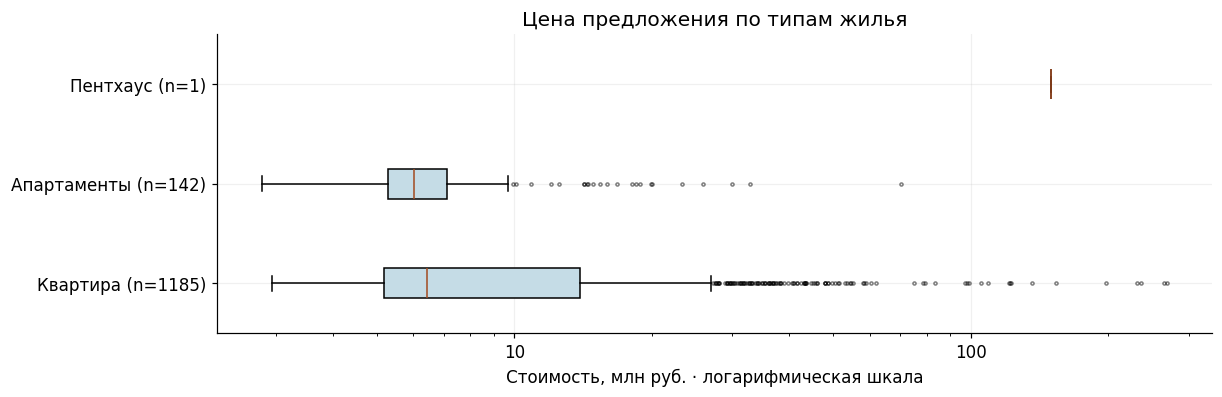

,n,"Цена Q1, млн руб.","Цена медиана, млн руб.","Цена Q3, млн руб.","Площадь медиана, м²",Медиана тыс. руб./м²
Группа,,,,,,
Квартира,1185,5.17,6.45,13.95,34.50,205.40
Апартаменты,142,5.28,6.01,7.12,27.11,223.90
Пентхаус,1,149.70,149.70,149.70,216.52,691.40


Показано 1328 из 1328 объявлений.


Комнатность,1-комнатная,2-комнатная,3-комнатная,4-комнатная,5-комнатная,Многокомнатная,Свободная планировка,Студия
Категория жилья,,,,,,,,
Апартаменты,23,8,7,0,0,0,0,104
Квартира,369,183,109,46,6,4,1,467
Пентхаус,0,0,0,0,0,1,0,0


In [147]:
type_summary = group_plot("Категория жилья", "Цена предложения по типам жилья",
                          ["Квартира", "Апартаменты", "Пентхаус"])
display(pd.crosstab(df["Категория жилья"], df["Комнатность"]).rename_axis(columns="Комнатность"))

**Интерпретация.** В выборке 1 185 квартир, 142 объекта с пометкой «Апартаменты» и один пентхаус. Медиана общей цены апартаментов ниже (6,01 против 6,45 млн руб.), но их медианная площадь меньше (27,11 против 34,50 м²), а медиана цены за м² выше (223,90 против 205,40 тыс. руб.). Среди апартаментов 104 студии. Поэтому общая цена без учёта площади и структуры предложения может дать неверное впечатление о различиях типов.

Пентхаус стоит 149,70 млн руб. при площади 216,52 м². Единственный объект остаётся в EDA и будущей постановке; его коробка фактически является точкой, а не оценкой распределения. Отдельную устойчивую модель или оценку качества для пентхаусов по этой выборке построить нельзя.

### 9.4. Отделка

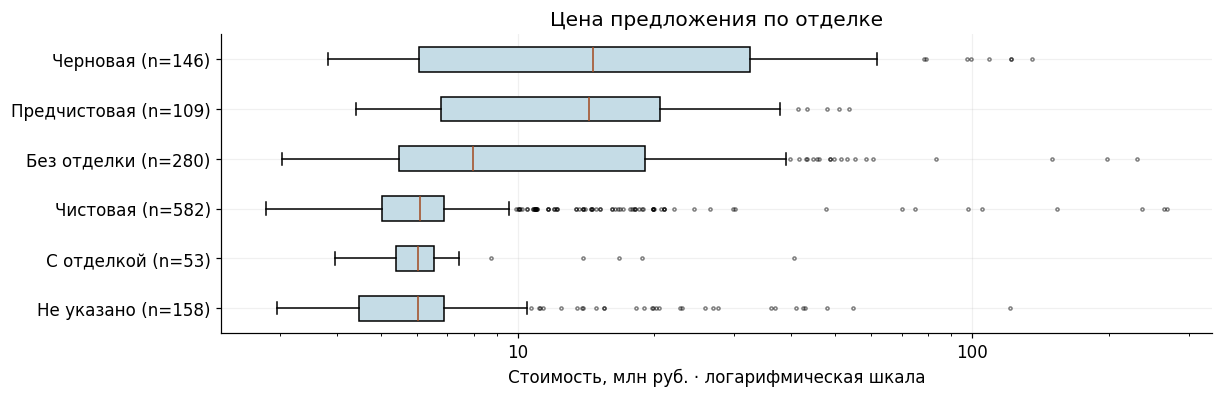

,n,"Цена Q1, млн руб.","Цена медиана, млн руб.","Цена Q3, млн руб.","Площадь медиана, м²",Медиана тыс. руб./м²
Группа,,,,,,
Не указано,158,4.47,6.02,6.90,33.52,181.70
С отделкой,53,5.40,6.05,6.54,28.38,211.06
Чистовая,582,5.02,6.10,6.90,28.62,198.20
Без отделки,280,5.49,7.99,19.08,39.38,228.38
Предчистовая,109,6.80,14.34,20.56,41.98,266.54
Черновая,146,6.05,14.63,32.42,47.32,249.10


Показано 1328 из 1328 объявлений.


In [148]:
finish_summary = group_plot("Отделка, категория", "Цена предложения по отделке")

**Интерпретация.** Самая частая категория — чистовая отделка (582 объявления), её медианная стоимость 6,10 млн руб. У черновой отделки (146 объектов) медиана 14,63 млн, у предчистовой (109) — 14,34 млн. Эти группы также имеют более крупные объекты и другую цену за м². Нельзя заключить, что наличие готовой отделки снижает цену: состав ЖК, районов и планировок различается. Для модели отделка — категориальный признак, без навязанного числового порядка. «С отделкой» оставляю отдельной исходной категорией: данных для точного отнесения к чистовой или предчистовой нет. У 158 объектов отделка неизвестна; удалять их из-за этого не нужно.

## 10. Этаж и этажность

Сравню первый, промежуточные и последний этажи и рассмотрю положение этажа относительно высоты дома. Правило построения категории не использует цену. В этой выборке нет одноэтажных домов; при их появлении первый этаж одновременно был бы последним, и это нужно учитывать.

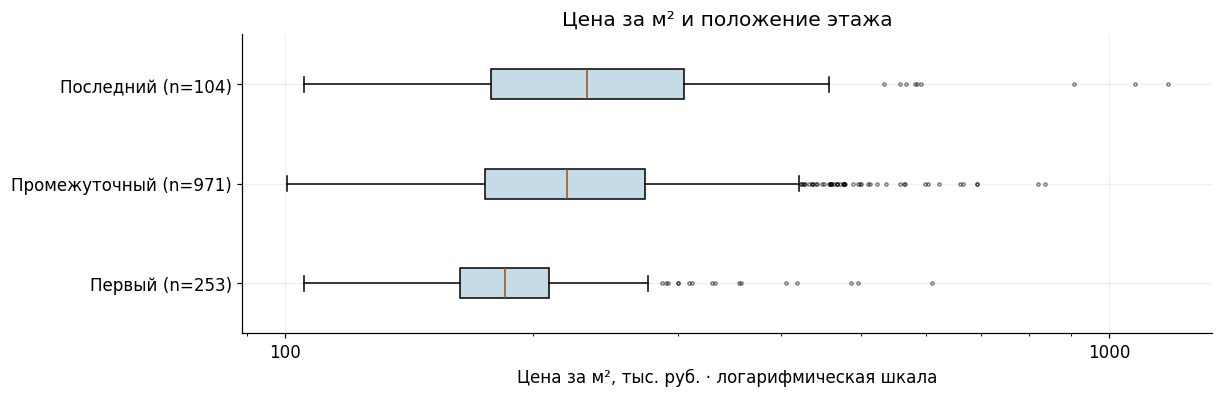

,n,"Цена Q1, млн руб.","Цена медиана, млн руб.","Цена Q3, млн руб.","Площадь медиана, м²",Медиана тыс. руб./м²
Группа,,,,,,
Первый,253,4.89,6.00,6.80,31.99,184.77
Промежуточный,971,5.35,6.50,14.03,34.15,220.27
Последний,104,5.05,6.93,21.50,35.94,232.42


Показано 1328 из 1328 объявлений.


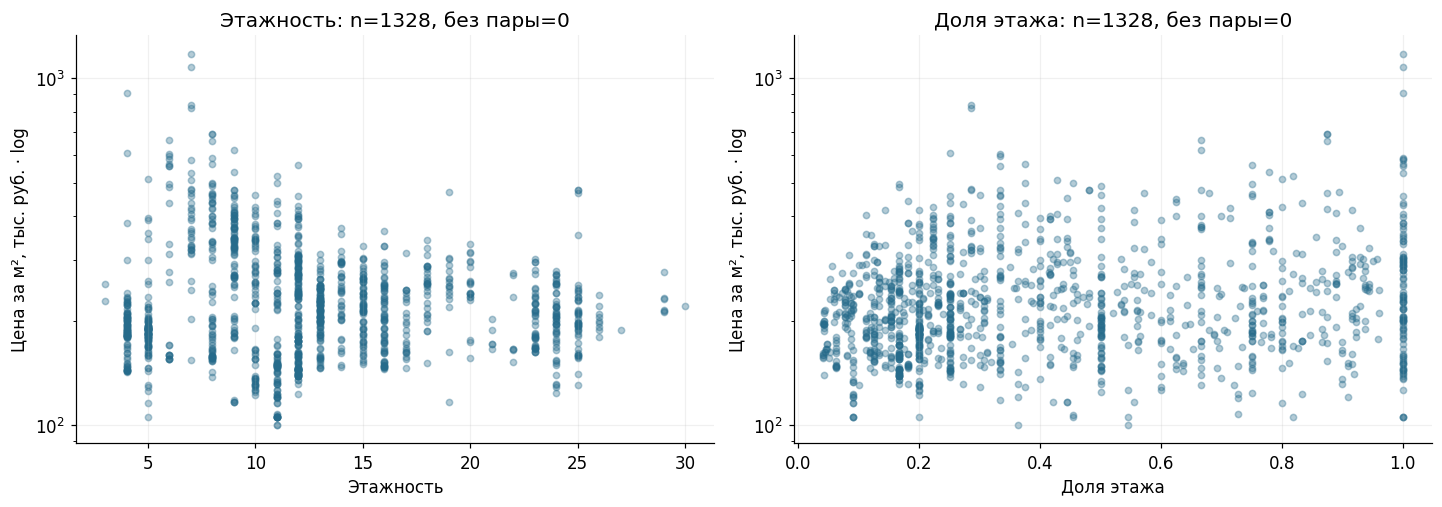

,Спирмен с ценой за м²
"Этаж, число",0.19
Этажность,0.00
Доля этажа,0.18


**Результат:** первый этаж — 253 объявлений, последний — 104; этажность домов от 3 до 30. Ранговая связь этажа с ценой за м² — 0.19, этажности — 0.00.

In [149]:
df["Положение этажа"] = pd.Series(pd.NA, index=df.index, dtype="string")
known_floor = df[["Этаж, число", "Этажность"]].notna().all(axis=1)
df.loc[known_floor, "Положение этажа"] = "Промежуточный"
df.loc[df["Первый этаж"].fillna(False), "Положение этажа"] = "Первый"
df.loc[df["Последний этаж"].fillna(False), "Положение этажа"] = "Последний"
floor_summary = group_plot("Положение этажа", "Цена за м² и положение этажа",
                           ["Первый", "Промежуточный", "Последний", "Не указано"], per_m2=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
for column, ax in zip(["Этажность", "Доля этажа"], axes):
    pair = df[[column, "Цена за м², тыс. руб."]].dropna()
    ax.scatter(pair[column], pair["Цена за м², тыс. руб."], s=17, alpha=0.35, color="#266B8B")
    ax.set_yscale("log")
    ax.set_xlabel(column)
    ax.set_ylabel("Цена за м², тыс. руб. · log")
    ax.set_title(f"{column}: n={len(pair)}, без пары={len(df) - len(pair)}")
plt.show()

floor_corr = df[["Этаж, число", "Этажность", "Доля этажа", "Цена за м², руб."]].astype(float).rank().corr()
display(floor_corr.loc[["Этаж, число", "Этажность", "Доля этажа"], ["Цена за м², руб."]]
        .rename(columns={"Цена за м², руб.": "Спирмен с ценой за м²"}))
display(Markdown(
    f"**Результат:** первый этаж — {int(df['Первый этаж'].sum())} объявлений, "
    f"последний — {int(df['Последний этаж'].sum())}; "
    f"этажность домов от {df['Этажность'].min()} до {df['Этажность'].max()}. "
    f"Ранговая связь этажа с ценой за м² — "
    f"{floor_corr.loc['Этаж, число', 'Цена за м², руб.']:.2f}, "
    f"этажности — {floor_corr.loc['Этажность', 'Цена за м², руб.']:.2f}."
))

**Интерпретация.** Связь этажа с ценой за м² слабее, чем связь общей площади с ценой; линейного правила «выше — дороже» для всей выборки недостаточно. У этажности ранговая корреляция с ценой за м² близка к нулю, но это не исключает нелинейных зависимостей и взаимодействия с ЖК. В модель стоит проверить абсолютный и относительный этаж, флаги первого/последнего, не трактуя групповые различия как причинную надбавку. На сравнении используются все объявления, так как этажи разобраны без пропусков.

## 11. Жилые комплексы и перенос на новые ЖК

Покажу распределение числа объявлений по ЖК и десять самых представленных комплексов. Ограничение топ-10 касается только подписи на графике; остальные объекты остаются в данных. Названия комплексов используются как записаны: возможные варианты написания не объединяются без проверки.

,n,"Цена Q1, млн руб.","Цена медиана, млн руб.","Цена Q3, млн руб.","Площадь медиана, м²",Медиана тыс. руб./м²
ЖК,,,,,,
ЖК «Полет»,40,3.37,4.07,4.85,33.49,120.96
ЖК «Parkolovo (Парколово)»,37,5.32,5.70,6.40,36.33,162.27
ЖК «Живи! в Рыбацком»,32,5.30,5.62,6.29,24.61,224.50
ЖК «Курортный Квартал»,31,5.13,5.95,6.53,32.05,184.88
ЖК «Цветной Город»,30,3.44,3.48,4.37,21.15,166.38
ЖК «Новое Колпино»,29,3.31,3.48,5.16,23.71,149.27
ЖК «ЮгТаун. Олимпийские кварталы»,28,4.83,6.32,6.79,35.42,176.14
ЖК «Univer City. Город возможностей»,24,4.64,6.03,6.45,32.95,184.27
ЖК «Зеленый квартал»,23,4.90,5.00,6.60,26.60,192.17


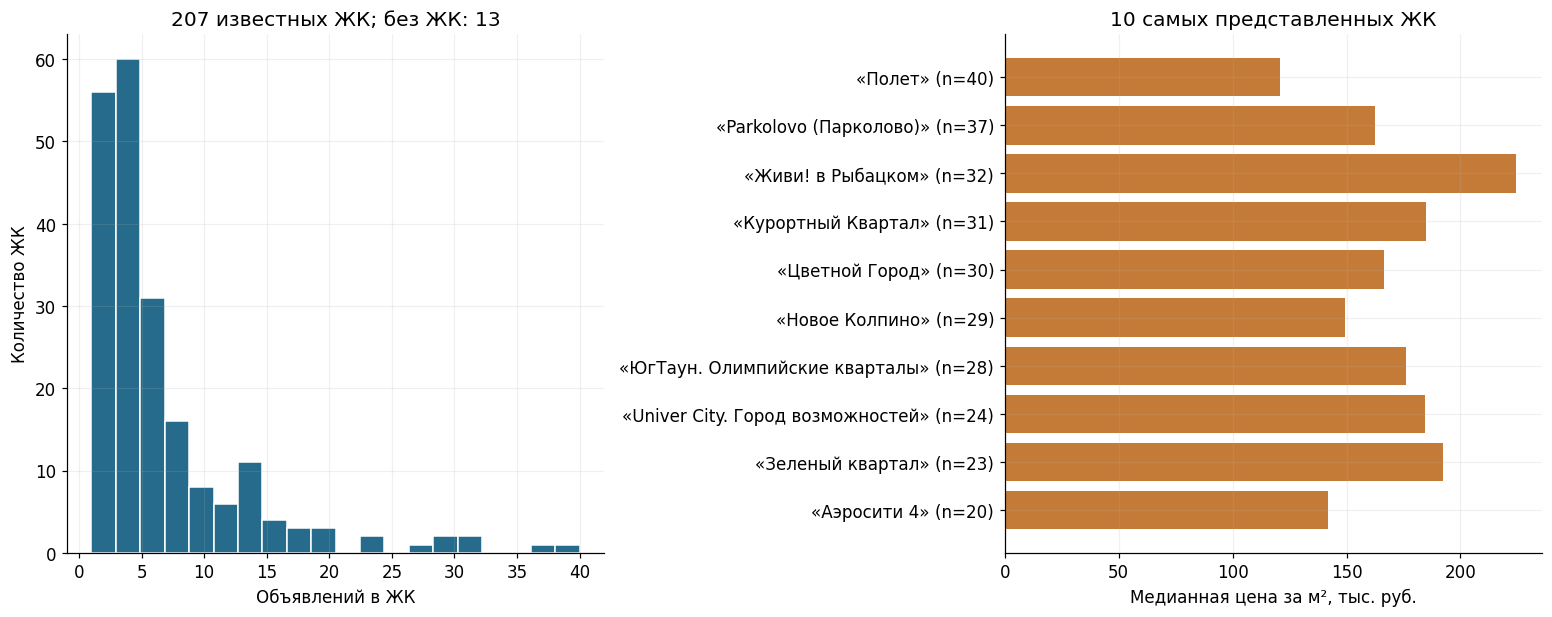

**Результат:** 207 известных ЖК, 31 представлены одним объявлением. Число объектов в топ-10 — 294 (22.1% выборки); вне топ-10 — 1034, включая 13 без названия ЖК. Наибольшая группа — ЖК «Полет» (40 объектов).

In [150]:
complex_counts = df["ЖК"].value_counts()
top_complexes = complex_counts.head(10).index
complex_summary = group_summary("ЖК")
display(complex_summary.loc[top_complexes])
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), layout="constrained")
axes[0].hist(complex_counts, bins=20, color="#266B8B", edgecolor="white")
axes[0].set_xlabel("Объявлений в ЖК")
axes[0].set_ylabel("Количество ЖК")
axes[0].set_title(f"{len(complex_counts)} известных ЖК; без ЖК: {df['ЖК'].isna().sum()}")
top = complex_summary.loc[top_complexes].iloc[::-1]
labels = [f"{name.removeprefix('ЖК ')} (n={row['n']:.0f})" for name, row in top.iterrows()]
axes[1].barh(labels, top["Медиана тыс. руб./м²"], color="#C47B38")
axes[1].set_xlabel("Медианная цена за м², тыс. руб.")
axes[1].set_title("10 самых представленных ЖК")
plt.show()
top_n = int(complex_counts.head(10).sum())
display(Markdown(
    f"**Результат:** {len(complex_counts)} известных ЖК, "
    f"{int(complex_counts.eq(1).sum())} представлены одним объявлением. "
    f"Число объектов в топ-10 — {top_n} ({top_n / len(df):.1%} выборки); "
    f"вне топ-10 — {len(df) - top_n}, включая {df['ЖК'].isna().sum()} без названия ЖК. "
    f"Наибольшая группа — {complex_counts.index[0]} ({complex_counts.iloc[0]} объектов)."
))

**Интерпретация.** В 207 известных ЖК цены за м² и размеры групп существенно различаются. Например, в наиболее представленных ЖК медианы составляют около 120,96 тыс. руб./м² у «Полета» и 224,50 тыс. у «Живи! в Рыбацком». ЖК может отражать местоположение и особенности проекта, но большое число редких названий создаёт риск запоминания.

В ДЗ 2 нужны два явно различающихся сценария: разбиение по объявлениям для похожих объектов в знакомых ЖК и **групповая валидация по ЖК** для переноса на новые комплексы. Во втором сценарии ни один известный ЖК не должен одновременно встречаться в обучении и проверке. Для 13 неизвестных ЖК понадобится заранее заданная политика (например, единая группа «ЖК неизвестен» с оговоркой, что это не реальный комплекс) и проверка результатов отдельно. Обычное случайное разбиение может завысить оценку переноса на новые проекты. Эта проверка ещё не выполнена: здесь нет обучения или оценки модели.

## 12. Пропуски и риск смещения выборки

Анализирую пропуски после удаления повторов и разбора полей. Для сравнения групп заполненности покажу количество объявлений и медианную цену, а для типов жилья — долю пропусков. Это описание совместной встречаемости, а не доказательство механизма возникновения пропусков.

,Пропусков,"Пропусков, %"
Парковка,981,73.87
Вид из окон,835,62.88
Санузел,727,54.74
Количество лифтов,714,53.77
"Площадь кухни, м²",544,40.96
"Потолки, м",435,32.76
"Жилая площадь, м²",226,17.02
Тип дома,212,15.96
"Отделка, категория",158,11.90
Метро,44,3.31


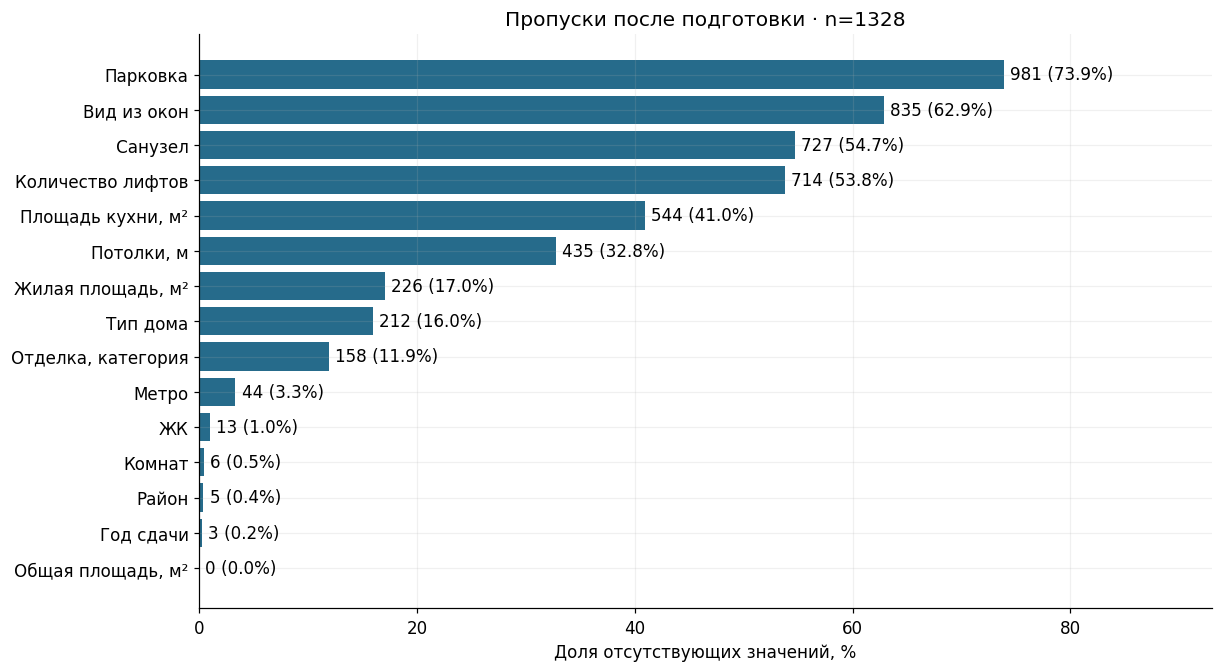

,Признак,Состояние,n,"Цена медиана, млн руб.","Площадь медиана, м²"
0,"Жилая площадь, м²",Заполнено,1102,6.40,33.50
1,"Жилая площадь, м²",Пропущено,226,6.40,36.58
2,"Площадь кухни, м²",Заполнено,784,6.87,37.31
3,"Площадь кухни, м²",Пропущено,544,5.79,26.80
4,"Потолки, м",Заполнено,893,6.54,34.10
5,"Потолки, м",Пропущено,435,5.99,33.30
6,"Отделка, категория",Заполнено,1170,6.45,33.80
7,"Отделка, категория",Пропущено,158,6.02,33.52
8,Парковка,Заполнено,347,6.85,34.51
9,Парковка,Пропущено,981,6.29,33.50


,n,"Жилая площадь, м²: NA, %","Площадь кухни, м²: NA, %","Потолки, м: NA, %","Отделка, категория: NA, %","Парковка: NA, %"
Категория жилья,,,,,,
Апартаменты,142,27.46,69.01,45.77,9.15,72.54
Квартира,1185,15.78,37.64,31.22,12.24,74.01
Пентхаус,1,0.00,0.00,0.00,0.00,100.00


,всего,осталось,потеряно,"потеряно, %"
Категория жилья,,,,
Апартаменты,142,42,100,70.42
Квартира,1185,709,476,40.17
Пентхаус,1,1,0,0.00


**Результат:** правило старого решения «оставить только полные три площади» сохранило бы 752 из 1328 уникальных объявлений и исключило бы 576 (43.4%). До дедупликации это правило даёт 794 из 1400 строк. В текущем EDA по необязательным пропускам исключено 0 строк.

In [151]:
missing_features = [*area_mapping.values(), "Потолки, м", "Комнат", "Район", "ЖК",
                    "Метро", "Год сдачи", "Отделка, категория", "Санузел",
                    "Вид из окон", "Количество лифтов", "Тип дома", "Парковка"]
missing_summary = pd.DataFrame({
    "Пропусков": df[missing_features].isna().sum(),
    "Пропусков, %": df[missing_features].isna().mean().mul(100),
}).sort_values("Пропусков", ascending=False)
display(missing_summary)
fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
ordered = missing_summary.iloc[::-1]
bars = ax.barh(ordered.index, ordered["Пропусков, %"], color="#266B8B")
ax.bar_label(bars, labels=[f"{count:.0f} ({pct:.1f}%)" for count, pct in ordered.to_numpy()], padding=4)
ax.set_xlim(0, 93)
ax.set_xlabel("Доля отсутствующих значений, %")
ax.set_title(f"Пропуски после подготовки · n={len(df)}")
plt.show()

selected_missing = ["Жилая площадь, м²", "Площадь кухни, м²", "Потолки, м",
                    "Отделка, категория", "Парковка"]
missing_groups = []
for column in selected_missing:
    for absent in [False, True]:
        group = df.loc[df[column].isna().eq(absent)]
        missing_groups.append({
            "Признак": column, "Состояние": "Пропущено" if absent else "Заполнено",
            "n": len(group), "Цена медиана, млн руб.": group["Стоимость, млн руб."].median(),
            "Площадь медиана, м²": group["Общая площадь, м²"].median(),
        })
display(pd.DataFrame(missing_groups))

missing_by_type = df.groupby("Категория жилья")[selected_missing].agg(lambda x: x.isna().mean() * 100)
missing_by_type.insert(0, "n", df.groupby("Категория жилья").size())
display(missing_by_type.rename(columns={c: f"{c}: NA, %" for c in selected_missing}))

old_columns = ["Стоимость", *area_mapping.values()]
old_complete = df[old_columns].notna().all(axis=1)
coverage = df.assign(Полные_три_площади=old_complete).groupby("Категория жилья").agg(
    всего=("Стоимость", "size"), осталось=("Полные_три_площади", "sum"),
)
coverage["потеряно"] = coverage["всего"] - coverage["осталось"]
coverage["потеряно, %"] = coverage["потеряно"] / coverage["всего"] * 100
display(coverage)
raw_complete = raw[["Стоимость", "Общая площадь", "Жилая площадь", "Площадь кухни"]].notna().all(axis=1)
display(Markdown(
    f"**Результат:** правило старого решения «оставить только полные три площади» "
    f"сохранило бы {int(old_complete.sum())} из {len(df)} уникальных объявлений "
    f"и исключило бы {int((~old_complete).sum())} ({(~old_complete).mean():.1%}). "
    f"До дедупликации это правило даёт {int(raw_complete.sum())} из {len(raw)} строк. "
    "В текущем EDA по необязательным пропускам исключено 0 строк."
))

**Интерпретация.** После дедупликации отсутствуют 544 значения площади кухни (41,0%), 435 высот потолков (32,8%) и 981 значение парковки (73,9%). Применение прежнего удаления неполных строк сократило бы набор до 752 уникальных объявлений и исключило 576 (43,4%). При этом потери неравномерны: 100 из 142 апартаментов (70,4%) против 476 из 1 185 квартир (40,2%). Значит, удаление по заполненности меняет представительство типов жилья.

У объектов с пропущенной площадью кухни медиана цены составляет 5,79 млн руб., а общей площади — 26,80 м²; при заполненной кухне — 6,87 млн руб. и 37,31 м². Пропуски связаны с составом объектов, поэтому считать их случайными без дальнейшей проверки нельзя. Полный набор характеристик не является условием включения в исследование.

Для ДЗ 2 следует проверить заполнение числовых признаков статистиками тренировочной выборки с индикаторами пропусков, отдельную неизвестную категорию для категориальных признаков или модели с поддержкой пропусков. Эти правила нужно обучать внутри каждого тренировочного фолда. Большое число пропусков не доказывает бесполезность признака, а различие цен между группами не доказывает причинную связь с отсутствием данных. Полезность парковки, вида из окон и других редких полей предстоит измерить.

## 13. Что изменится относительно прежнего решения

В прежнем ноутбуке `supervised-Ultimatereo/main.ipynb` использовались только **общая, жилая и кухонная площади**; строки с пропусками удалялись. Нормализация min–max выполнялась для всей таблицы **до разбиения**, включая целевую переменную. Следовательно, параметры преобразований учитывали отложенные наблюдения. Перемешивание также не имело фиксированного seed. Это не позволяет считать прежнюю оценку надёжным ориентиром для честного сравнения.

Текущий EDA расширяет возможные направления улучшения: комнатность и студия, район, тип жилья, отделка, этажность, относительный этаж и ЖК. Сохранение объектов с необязательными пропусками увеличивает покрытие. **Само улучшение качества ещё предстоит измерить** на одинаковом корректном разбиении и в исходных рублях; больше признаков не гарантирует лучшую модель.

### 13.1. Контракт будущих входов

В таблице ниже явно зафиксирован предварительный список кандидатов. Список не означает, что все они обязательно улучшат прогноз. Потребуются кодирование категорий, обработка пропусков и оценка на валидации.

In [152]:
numeric_candidates = [*area_mapping.values(), "Потолки, м", "Этаж, число", "Этажность",
                      "Доля этажа", "Комнат", "Год сдачи"]
binary_candidates = ["Студия", "Первый этаж", "Последний этаж"]
categorical_candidates = ["Комнатность", "Район", "Категория жилья", "Отделка, категория",
                          "ЖК", "Метро", "Санузел", "Вид из окон", "Количество лифтов",
                          "Тип дома", "Парковка"]
candidate_features = numeric_candidates + binary_candidates + categorical_candidates
excluded_inputs = ["Стоимость", "Стоимость, млн руб.", "Цена за м², руб.",
                   "Цена за м², тыс. руб.", LINK, "Локальное место", "Просмотры",
                   "Название", "Адрес", "Строка Excel"]
assert set(candidate_features).isdisjoint(excluded_inputs)
display(pd.DataFrame([
    {"Группа": "Числовые", "Признаки": ", ".join(numeric_candidates)},
    {"Группа": "Двоичные", "Признаки": ", ".join(binary_candidates)},
    {"Группа": "Категориальные / требуют разбора", "Признаки": ", ".join(categorical_candidates)},
    {"Группа": "Исключены из входов", "Признаки": ", ".join(excluded_inputs)},
]).style.set_properties(**{"white-space": "normal", "text-align": "left"}))

,Группа,Признаки
0,Числовые,"Общая площадь, м², Жилая площадь, м², Площадь кухни, м², Потолки, м, Этаж, число, Этажность, Доля этажа, Комнат, Год сдачи"
1,Двоичные,"Студия, Первый этаж, Последний этаж"
2,Категориальные / требуют разбора,"Комнатность, Район, Категория жилья, Отделка, категория, ЖК, Метро, Санузел, Вид из окон, Количество лифтов, Тип дома, Парковка"
3,Исключены из входов,"Стоимость, Стоимость, млн руб., Цена за м², руб., Цена за м², тыс. руб., Ссылка на страницу, Локальное место, Просмотры, Название, Адрес, Строка Excel"


Цена за м² — прямое преобразование цели, поэтому её включение создало бы утечку. Ссылки и локальные пути — идентификаторы сбора, просмотры зависят от экспозиции объявления. Название и адрес используются только для извлечения характеристик; сырые строки в приведённый набор входов не входят. Производная комнатность и число комнат частично дублируют друг друга: их совместную полезность нужно проверить, а не автоматически включать оба признака в финальную модель.

### 13.2. План ДЗ 2

1. Зафиксировать отложенную выборку и seed 42, исключив попадание одинаковых ссылок в разные части. Сравнить сценарий знакомых ЖК с переносом на новые ЖК через групповую валидацию. Не использовать тест для выбора гиперпараметров.
2. В каждом тренировочном фолде отдельно обучать заполнение пропусков, кодирование категорий, объединение редких уровней и масштабирование. Детерминированный разбор единиц и названий, выполненный здесь, не оценивает параметры по распределению данных. Статистики всего EDA, включая IQR, не переносить как обученные пороги в модель.
3. Измерить MAE и RMSE константного бейзлайна и модели с тремя площадями на том же разбиении, затем сравнить с расширенным набором. Константу и все параметры преобразований определять только по обучению.
4. Проверить преобразование цели и более сложные модели. Если цель преобразуется, возвращать прогнозы в рубли перед оценкой. Параметры обучаемого преобразования цели также оценивать только на обучении.
5. Отдельно показать ошибки по типу жилья, комнатности, районам и ценовым сегментам вместе с `n`; проверить чувствительность к дорогому хвосту и двум высотам потолков 7 м. Малые группы не позволяют делать точные выводы.

EDA выполнен на всей имеющейся выборке по условию ДЗ. Будущий тест из неё будет отложенным для обучения, но уже не полностью «непросмотренным» при исследовании. Для независимой итоговой проверки и переноса на текущий рынок нужны новые данные с датами. Здесь модели не обучаются, метрики качества не заявляются.

Финальная ячейка проверяет сохранение объёма данных, воспроизводимость ключевых подсчётов, отсутствие запрещённых входов и сохранность исходного Excel. Числа относятся именно к приложенному снимку данных; при замене источника ожидания нужно пересмотреть.

In [153]:
assert raw.shape == (1400, 21)
assert raw[LINK].nunique() == 1328
assert len(df) == 1328 and not df[LINK].duplicated().any()
assert int(removed_duplicate_mask.sum()) == 72
assert int(business_conflicts.sum()) == 0
assert int(conflict_counts["Просмотры"]) == 4
assert df["Категория жилья"].value_counts().to_dict() == {
    "Квартира": 1185, "Апартаменты": 142, "Пентхаус": 1,
}
assert valid_price_area.all()
assert int(df["Комнат"].isna().sum()) == 6
assert int(df["Район"].isna().sum()) == 5
assert int(old_complete.sum()) == 752
assert set(candidate_features).isdisjoint(excluded_inputs)
assert row_audit["Удалено на этапе"].sum() == len(raw) - len(df)
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == source_hash
print("Проверки пройдены: 1 328 строк; удалены только 72 повтора URL.")
print("Все типы жилья сохранены; необязательные пропуски не исключают объекты.")
print("Исходный файл не изменён. Обучение моделей оставлено для ДЗ 2.")

Проверки пройдены: 1 328 строк; удалены только 72 повтора URL.
Все типы жилья сохранены; необязательные пропуски не исключают объекты.
Исходный файл не изменён. Обучение моделей оставлено для ДЗ 2.
